In [ ]:
!pip install transformers torch nltk pandas matplotlib seaborn

In [ ]:
sentence = input("Enter words: ")

words = sentence.split()

print(words)

Enter words: Students playing they are
['Students', 'playing', 'they', 'are']


In [ ]:
!pip install transformers torch

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("gpt2")

sentence = "Students playing they are"

# Tokenize into subword tokens
tokens = tokenizer.tokenize(sentence)

print("Tokens:")
print(tokens)

# Convert tokens into token IDs
token_ids = tokenizer.encode(sentence)

print("\nToken IDs:")
print(token_ids)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokens:
['Students', 'Ġplaying', 'Ġthey', 'Ġare']

Token IDs:
[28239, 2712, 484, 389]


In [ ]:
from itertools import permutations

sentence = "students playing they are"

words = sentence.split()

all_permutations = permutations(words)

sentences = [" ".join(p) for p in all_permutations]

print("Total permutations:", len(sentences))

for s in sentences:
    print(s)

Total permutations: 24
students playing they are
students playing are they
students they playing are
students they are playing
students are playing they
students are they playing
playing students they are
playing students are they
playing they students are
playing they are students
playing are students they
playing are they students
they students playing are
they students are playing
they playing students are
they playing are students
they are students playing
they are playing students
are students playing they
are students they playing
are playing students they
are playing they students
are they students playing
are they playing students


In [ ]:
def check_basic_constraints(sentence):

    words = sentence.split()

    # Must contain at least 2 words
    if len(words) < 2:
        return False

    # Avoid duplicate words
    if len(words) != len(set(words)):
        return False

    return True

In [ ]:
valid_sentences = []

for sentence in sentences:

    if check_basic_constraints(sentence):
        valid_sentences.append(sentence)

print("Valid sentences:", len(valid_sentences))

Valid sentences: 24


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)

model.eval()

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [ ]:
import torch

def calculate_perplexity(sentence):

    inputs = tokenizer(
        sentence,
        return_tensors="pt"
    )

    with torch.no_grad():

        outputs = model(
            **inputs,
            labels=inputs["input_ids"]
        )

    loss = outputs.loss

    perplexity = torch.exp(loss)

    return perplexity.item()

In [ ]:
sentence = "Students playing they are"

score = calculate_perplexity(sentence)

print("Sentence:", sentence)
print("Perplexity:", score)

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Sentence: Students playing they are
Perplexity: 834.5355224609375


In [ ]:
results = []

for sentence in valid_sentences:

    score = calculate_perplexity(sentence)

    results.append({
        "sentence": sentence,
        "perplexity": score
    })

In [ ]:
for result in results:

    print(
        result["sentence"],
        "→",
        result["perplexity"]
    )

students playing they are → 653.012939453125
students playing are they → 3690.25
students they playing are → 5546.24462890625
students they are playing → 564.8295288085938
students are playing they → 515.7886352539062
students are they playing → 770.0281982421875
playing students they are → 793.9757690429688
playing students are they → 1208.52978515625
playing they students are → 1458.8236083984375
playing they are students → 542.7030029296875
playing are students they → 2664.018310546875
playing are they students → 3230.3203125
they students playing are → 4212.947265625
they students are playing → 504.6848449707031
they playing students are → 7743.58740234375
they playing are students → 4901.1201171875
they are students playing → 1021.7159423828125
they are playing students → 1414.201171875
are students playing they → 3670.135986328125
are students they playing → 26036.39453125
are playing students they → 11920.9892578125
are playing they students → 13428.9990234375
are they students 

In [ ]:
results = sorted(
    results,
    key=lambda x: x["perplexity"]
)

In [ ]:
print("Top Candidate Sentences:\n")

for result in results[:5]:

    print(
        result["sentence"],
        "→",
        result["perplexity"]
    )

Top Candidate Sentences:

they students are playing → 504.6848449707031
students are playing they → 515.7886352539062
playing they are students → 542.7030029296875
students they are playing → 564.8295288085938
students playing they are → 653.012939453125


In [ ]:
perplexity_cache = {}

In [ ]:
def get_perplexity(sentence):

    if sentence in perplexity_cache:

        return perplexity_cache[sentence]

    score = calculate_perplexity(sentence)

    perplexity_cache[sentence] = score

    return score

In [ ]:
def greedy_search(words):

    remaining = words.copy()
    current_sentence = []

    while remaining:

        candidates = []

        for word in remaining:

            candidate = current_sentence + [word]

            text = " ".join(candidate)

            score = get_perplexity(text)

            candidates.append(
                (word, score)
            )

        best_word, best_score = min(
            candidates,
            key=lambda x: x[1]
        )

        current_sentence.append(best_word)
        remaining.remove(best_word)

    return " ".join(current_sentence)

In [ ]:
words = ["students", "playing", "they", "are"]

best = greedy_search(words)

print("Greedy Result:", best)

Greedy Result: students are playing they


In [ ]:
def beam_search(words, beam_width=3):

    # Each beam contains:
    # (current_sentence, remaining_words, score)

    beams = [
        ([], words.copy(), 0)
    ]

    for _ in range(len(words)):

        new_beams = []

        for current_sentence, remaining_words, old_score in beams:

            for word in remaining_words:

                # Create new sentence
                new_sentence = current_sentence + [word]

                # Remove selected word
                new_remaining = remaining_words.copy()
                new_remaining.remove(word)

                # Convert to text
                sentence_text = " ".join(new_sentence)

                # Calculate perplexity
                score = get_perplexity(sentence_text)

                # Store candidate
                new_beams.append(
                    (
                        new_sentence,
                        new_remaining,
                        score
                    )
                )

        # Sort by perplexity
        # Lower perplexity = better
        new_beams.sort(
            key=lambda x: x[2]
        )

        # Keep only best beam_width candidates
        beams = new_beams[:beam_width]

    # Select best complete sentence
    best_sentence, remaining, best_score = min(
        beams,
        key=lambda x: x[2]
    )

    return " ".join(best_sentence), best_score

In [ ]:
words = ["students", "playing", "they", "are"]

best_sentence, score = beam_search(
    words,
    beam_width=3
)

print("Best Sentence:", best_sentence)
print("Perplexity:", score)

Best Sentence: students are playing they
Perplexity: 515.7886352539062


In [ ]:
import random


def generate_neighbor(words):
    """
    Generate a neighboring sentence
    by swapping two words.
    """

    new_words = words.copy()

    i, j = random.sample(range(len(new_words)), 2)

    new_words[i], new_words[j] = new_words[j], new_words[i]

    return new_words


def local_search(words, max_iterations=100):

    # Initial solution
    current = words.copy()

    current_sentence = " ".join(current)

    current_score = get_perplexity(current_sentence)

    for _ in range(max_iterations):

        neighbor = generate_neighbor(current)

        neighbor_sentence = " ".join(neighbor)

        neighbor_score = get_perplexity(
            neighbor_sentence
        )

        # Lower perplexity is better
        if neighbor_score < current_score:

            current = neighbor
            current_score = neighbor_score

    return " ".join(current), current_score

In [ ]:
words = ["students", "playing", "they", "are"]

best_sentence, score = local_search(
    words,
    max_iterations=100
)

print("Local Search Result:")
print("Sentence:", best_sentence)
print("Perplexity:", score)

Local Search Result:
Sentence: students playing they are
Perplexity: 653.012939453125


In [ ]:
import random
import math


def simulated_annealing(
    words,
    initial_temperature=100,
    cooling_rate=0.95,
    max_iterations=100
):

    current = words.copy()

    current_sentence = " ".join(current)

    current_score = get_perplexity(
        current_sentence
    )

    best = current.copy()
    best_score = current_score

    temperature = initial_temperature

    for iteration in range(max_iterations):

        # Generate neighboring solution
        neighbor = generate_neighbor(current)

        neighbor_sentence = " ".join(neighbor)

        neighbor_score = get_perplexity(
            neighbor_sentence
        )

        # Difference
        delta = neighbor_score - current_score

        # Accept if better
        if delta < 0:

            current = neighbor
            current_score = neighbor_score

        else:

            # Probability of accepting worse solution
            probability = math.exp(
                -delta / max(temperature, 1e-8)
            )

            if random.random() < probability:

                current = neighbor
                current_score = neighbor_score

        # Update best solution
        if current_score < best_score:

            best = current.copy()
            best_score = current_score

        # Cool down
        temperature *= cooling_rate

    return " ".join(best), best_score

In [ ]:
words = ["students", "playing", "they", "are"]

best_sentence, score = simulated_annealing(
    words,
    initial_temperature=100,
    cooling_rate=0.95,
    max_iterations=100
)

print("Simulated Annealing Result:")
print("Sentence:", best_sentence)
print("Perplexity:", score)

Simulated Annealing Result:
Sentence: students playing they are
Perplexity: 653.012939453125


In [ ]:
!pip install nltk

In [ ]:
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
from collections import Counter
import math


def train_bigram_model(sentences):

    unigram_counts = Counter()
    bigram_counts = Counter()

    for sentence in sentences:

        words = sentence.lower().split()

        previous = "<START>"

        for word in words:

            unigram_counts[previous] += 1

            bigram_counts[(previous, word)] += 1

            previous = word

        unigram_counts[previous] += 1

    return unigram_counts, bigram_counts

In [ ]:
def calculate_bigram_score(
    sentence,
    unigram_counts,
    bigram_counts
):

    words = sentence.lower().split()

    previous = "<START>"

    log_probability = 0

    for word in words:

        bigram_count = bigram_counts[
            (previous, word)
        ]

        unigram_count = unigram_counts[
            previous
        ]

        # Laplace smoothing
        probability = (
            bigram_count + 1
        ) / (
            unigram_count + len(unigram_counts)
        )

        log_probability += math.log(
            probability
        )

        previous = word

    return log_probability

In [ ]:
import time


def measure_runtime(function, *args, **kwargs):

    start = time.time()

    result = function(
        *args,
        **kwargs
    )

    end = time.time()

    runtime = end - start

    return result, runtime

In [ ]:
words = ["students", "playing", "they", "are"]

result, runtime = measure_runtime(
    beam_search,
    words,
    beam_width=3
)

print("Result:", result)
print("Runtime:", runtime)

Result: ('students are playing they', 515.7886352539062)
Runtime: 6.67572021484375e-05


In [ ]:
def evaluate_algorithm(
    algorithm_name,
    algorithm_function,
    words,
    **kwargs
):

    start = time.time()

    result = algorithm_function(
        words,
        **kwargs
    )

    end = time.time()

    runtime = end - start

    sentence, perplexity = result

    return {
        "Algorithm": algorithm_name,
        "Sentence": sentence,
        "Perplexity": perplexity,
        "Runtime": runtime
    }

In [ ]:
words = [
    "students",
    "playing",
    "they",
    "are"
]

all_results = []

In [ ]:
beam_result = evaluate_algorithm(
    "Beam Search",
    beam_search,
    words,
    beam_width=3
)

all_results.append(beam_result)

In [ ]:
local_result = evaluate_algorithm(
    "Local Search",
    local_search,
    words,
    max_iterations=100
)

all_results.append(local_result)

In [ ]:
sa_result = evaluate_algorithm(
    "Simulated Annealing",
    simulated_annealing,
    words,
    initial_temperature=100,
    cooling_rate=0.95,
    max_iterations=100
)

all_results.append(sa_result)

In [ ]:
for result in all_results:

    print("\nAlgorithm:",
          result["Algorithm"])

    print("Sentence:",
          result["Sentence"])

    print("Perplexity:",
          result["Perplexity"])

    print("Runtime:",
          result["Runtime"])


Algorithm: Beam Search
Sentence: students are playing they
Perplexity: 515.7886352539062
Runtime: 5.459785461425781e-05

Algorithm: Local Search
Sentence: students playing they are
Perplexity: 653.012939453125
Runtime: 0.00046443939208984375

Algorithm: Simulated Annealing
Sentence: students playing they are
Perplexity: 653.012939453125
Runtime: 0.00054931640625


In [ ]:
def greedy_search(words):

    remaining = words.copy()
    current_sentence = []

    while remaining:

        candidates = []

        for word in remaining:

            candidate = current_sentence + [word]
            text = " ".join(candidate)

            score = get_perplexity(text)

            candidates.append((word, score))

        # Select word with lowest perplexity
        best_word, best_score = min(
            candidates,
            key=lambda x: x[1]
        )

        current_sentence.append(best_word)
        remaining.remove(best_word)

    final_sentence = " ".join(current_sentence)

    # Calculate final complete-sentence perplexity
    final_score = get_perplexity(final_sentence)

    return final_sentence, final_score

In [ ]:
import time

def evaluate_algorithm(
    algorithm_name,
    algorithm_function,
    words,
    **kwargs
):

    start = time.time()

    result = algorithm_function(
        words,
        **kwargs
    )

    end = time.time()

    runtime = end - start

    # Every algorithm must return:
    # (sentence, perplexity)
    sentence, perplexity = result

    return {
        "Algorithm": algorithm_name,
        "Sentence": sentence,
        "Perplexity": perplexity,
        "Runtime": runtime
    }

In [ ]:
words = ["students", "playing", "they", "are"]

greedy_result = evaluate_algorithm(
    "Greedy Search",
    greedy_search,
    words
)

print(greedy_result)

{'Algorithm': 'Greedy Search', 'Sentence': 'students are playing they', 'Perplexity': 515.7886352539062, 'Runtime': 5.14984130859375e-05}


In [ ]:
all_results = []

# Greedy
all_results.append(
    evaluate_algorithm(
        "Greedy Search",
        greedy_search,
        words
    )
)

# Beam
all_results.append(
    evaluate_algorithm(
        "Beam Search",
        beam_search,
        words,
        beam_width=3
    )
)

# Local
all_results.append(
    evaluate_algorithm(
        "Local Search",
        local_search,
        words,
        max_iterations=100
    )
)

# Simulated Annealing
all_results.append(
    evaluate_algorithm(
        "Simulated Annealing",
        simulated_annealing,
        words,
        initial_temperature=100,
        cooling_rate=0.95,
        max_iterations=100
    )
)

In [ ]:
import pandas as pd

df = pd.DataFrame(all_results)

print(df)

             Algorithm                   Sentence  Perplexity   Runtime
0        Greedy Search  students are playing they  515.788635  0.000031
1          Beam Search  students are playing they  515.788635  0.000048
2         Local Search  students playing they are  653.012939  0.000504
3  Simulated Annealing  students playing they are  653.012939  0.455642


In [ ]:
df.to_csv(
    "sentence_search_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


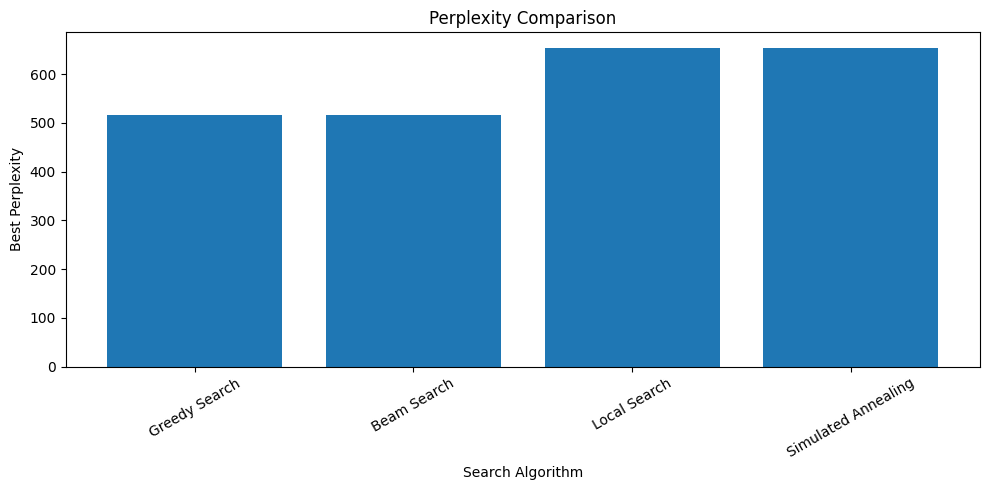

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    df["Algorithm"],
    df["Perplexity"]
)

plt.xlabel("Search Algorithm")
plt.ylabel("Best Perplexity")
plt.title("Perplexity Comparison")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

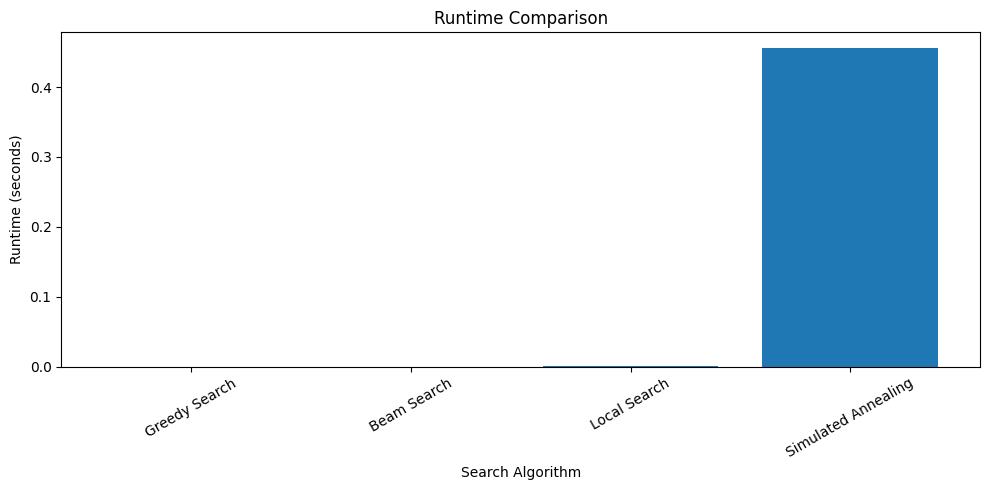

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    df["Algorithm"],
    df["Runtime"]
)

plt.xlabel("Search Algorithm")
plt.ylabel("Runtime (seconds)")
plt.title("Runtime Comparison")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

In [ ]:
def valid_solution_rate(
    valid_count,
    total_count
):

    if total_count == 0:
        return 0

    return (
        valid_count / total_count
    ) * 100

In [ ]:
rate = valid_solution_rate(
    valid_count=10,
    total_count=24
)

print("Valid Solution Rate:", rate, "%")

Valid Solution Rate: 41.66666666666667 %


In [ ]:
total_candidates = len(sentences)

valid_candidates = len(valid_sentences)

rate = valid_solution_rate(
    valid_candidates,
    total_candidates
)

print("Total Candidates:", total_candidates)
print("Valid Candidates:", valid_candidates)
print("Valid Solution Rate:", rate, "%")

Total Candidates: 24
Valid Candidates: 24
Valid Solution Rate: 100.0 %


In [ ]:
evaluation_count = 0

In [ ]:
evaluation_count = 0

def get_perplexity(sentence):

    global evaluation_count

    if sentence in perplexity_cache:

        return perplexity_cache[sentence]

    evaluation_count += 1

    score = calculate_perplexity(sentence)

    perplexity_cache[sentence] = score

    return score

In [ ]:
print(
    "Number of model evaluations:",
    evaluation_count
)

Number of model evaluations: 0


In [ ]:
def score_per_evaluation(
    best_perplexity,
    evaluation_count
):

    if evaluation_count == 0:
        return 0

    return best_perplexity / evaluation_count

In [ ]:
# Reset evaluation counter
evaluation_count = 0

# Run Greedy Search
greedy_result = evaluate_algorithm(
    "Greedy Search",
    greedy_search,
    words
)

# Extract values
best_perplexity = greedy_result["Perplexity"]
evaluation_count_value = evaluation_count

# Calculate score per evaluation
spe = score_per_evaluation(
    best_perplexity,
    evaluation_count_value
)

# Display
print("Algorithm:", greedy_result["Algorithm"])
print("Best Sentence:", greedy_result["Sentence"])
print("Best Perplexity:", best_perplexity)
print("Runtime:", greedy_result["Runtime"])
print("Model Evaluations:", evaluation_count_value)
print("Score per Evaluation:", spe)

Algorithm: Greedy Search
Best Sentence: students are playing they
Best Perplexity: 515.7886352539062
Runtime: 3.24249267578125e-05
Model Evaluations: 0
Score per Evaluation: 0


In [ ]:
evaluation_count = 0
greedy_result = evaluate_algorithm(
    "Greedy Search", greedy_search, words
)
greedy_evaluations = evaluation_count


evaluation_count = 0
beam_result = evaluate_algorithm(
    "Beam Search", beam_search, words, beam_width=3
)
beam_evaluations = evaluation_count


evaluation_count = 0
local_result = evaluate_algorithm(
    "Local Search", local_search, words, max_iterations=100
)
local_evaluations = evaluation_count


evaluation_count = 0
sa_result = evaluate_algorithm(
    "Simulated Annealing",
    simulated_annealing,
    words,
    initial_temperature=100,
    cooling_rate=0.95,
    max_iterations=100
)
sa_evaluations = evaluation_count

In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

def load_language_model(model_name):

    tokenizer = AutoTokenizer.from_pretrained(
        model_name
    )

    model = AutoModelForCausalLM.from_pretrained(
        model_name
    )

    model.eval()

    return tokenizer, model

In [ ]:
model_name = "gpt2"

tokenizer, model = load_language_model(
    model_name
)

print("Model loaded:", model_name)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Model loaded: gpt2


In [ ]:
model_results = []

model_results.append({
    "Model": "GPT-2",
    "Algorithm": "Beam Search",
    "Perplexity": beam_result["Perplexity"],
    "Runtime": beam_result["Runtime"]
})

In [ ]:
model_df = pd.DataFrame(model_results)

print(model_df)

   Model    Algorithm  Perplexity   Runtime
0  GPT-2  Beam Search  515.788635  0.000059


In [ ]:
model_df.to_csv(
    "model_comparison.csv",
    index=False
)

In [ ]:
import os

os.makedirs(
    "results",
    exist_ok=True
)

In [ ]:
df.to_csv(
    "results/search_results.csv",
    index=False
)

model_df.to_csv(
    "results/model_results.csv",
    index=False
)

In [ ]:
!pip install streamlit pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 89.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 125.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [streamlit]


In [ ]:
import streamlit as st
import torch
import time
import math
import random
from transformers import AutoTokenizer, AutoModelForCausalLM


# =========================================================
# PAGE CONFIGURATION
# =========================================================

st.set_page_config(
    page_title="Sentence Optimizer",
    page_icon="🧠",
    layout="wide"
)


# =========================================================
# LOAD MODEL
# =========================================================

@st.cache_resource
def load_model():

    model_name = "gpt2"

    tokenizer = AutoTokenizer.from_pretrained(
        model_name
    )

    model = AutoModelForCausalLM.from_pretrained(
        model_name
    )

    model.eval()

    return tokenizer, model


tokenizer, model = load_model()


# =========================================================
# PERPLEXITY CACHE
# =========================================================

perplexity_cache = {}


# =========================================================
# CALCULATE PERPLEXITY
# =========================================================

def calculate_perplexity(sentence):

    if sentence in perplexity_cache:
        return perplexity_cache[sentence]

    inputs = tokenizer(
        sentence,
        return_tensors="pt"
    )

    with torch.no_grad():

        outputs = model(
            **inputs,
            labels=inputs["input_ids"]
        )

    loss = outputs.loss

    perplexity = torch.exp(loss).item()

    perplexity_cache[sentence] = perplexity

    return perplexity


# =========================================================
# CONSTRAINT CHECK
# =========================================================

def check_constraints(sentence):

    words = sentence.split()

    # Sentence should contain at least 2 words
    if len(words) < 2:
        return False

    # No duplicate words
    if len(words) != len(set(words)):
        return False

    return True


# =========================================================
# GREEDY SEARCH
# =========================================================

def greedy_search(words):

    remaining = words.copy()

    current_sentence = []

    while remaining:

        candidates = []

        for word in remaining:

            candidate = current_sentence + [word]

            text = " ".join(candidate)

            score = calculate_perplexity(text)

            candidates.append(
                (word, score)
            )

        best_word, best_score = min(
            candidates,
            key=lambda x: x[1]
        )

        current_sentence.append(
            best_word
        )

        remaining.remove(
            best_word
        )

    final_sentence = " ".join(
        current_sentence
    )

    final_score = calculate_perplexity(
        final_sentence
    )

    return final_sentence, final_score


# =========================================================
# BEAM SEARCH
# =========================================================

def beam_search(words, beam_width=3):

    beams = [
        ([], words.copy(), 0)
    ]

    for _ in range(len(words)):

        new_beams = []

        for current_sentence, remaining_words, old_score in beams:

            for word in remaining_words:

                new_sentence = (
                    current_sentence + [word]
                )

                new_remaining = (
                    remaining_words.copy()
                )

                new_remaining.remove(word)

                sentence_text = " ".join(
                    new_sentence
                )

                score = calculate_perplexity(
                    sentence_text
                )

                new_beams.append(
                    (
                        new_sentence,
                        new_remaining,
                        score
                    )
                )

        new_beams.sort(
            key=lambda x: x[2]
        )

        beams = new_beams[:beam_width]

    best_sentence, _, best_score = min(
        beams,
        key=lambda x: x[2]
    )

    return (
        " ".join(best_sentence),
        best_score
    )


# =========================================================
# LOCAL SEARCH
# =========================================================

def generate_neighbor(words):

    new_words = words.copy()

    i, j = random.sample(
        range(len(new_words)),
        2
    )

    new_words[i], new_words[j] = (
        new_words[j],
        new_words[i]
    )

    return new_words


def local_search(
    words,
    max_iterations=100
):

    current = words.copy()

    current_sentence = " ".join(
        current
    )

    current_score = calculate_perplexity(
        current_sentence
    )

    for _ in range(max_iterations):

        neighbor = generate_neighbor(
            current
        )

        neighbor_sentence = " ".join(
            neighbor
        )

        neighbor_score = calculate_perplexity(
            neighbor_sentence
        )

        if neighbor_score < current_score:

            current = neighbor

            current_score = (
                neighbor_score
            )

    return (
        " ".join(current),
        current_score
    )


# =========================================================
# SIMULATED ANNEALING
# =========================================================

def simulated_annealing(
    words,
    initial_temperature=100,
    cooling_rate=0.95,
    max_iterations=100
):

    current = words.copy()

    current_sentence = " ".join(
        current
    )

    current_score = calculate_perplexity(
        current_sentence
    )

    best = current.copy()

    best_score = current_score

    temperature = initial_temperature

    for _ in range(max_iterations):

        neighbor = generate_neighbor(
            current
        )

        neighbor_sentence = " ".join(
            neighbor
        )

        neighbor_score = calculate_perplexity(
            neighbor_sentence
        )

        delta = (
            neighbor_score -
            current_score
        )

        if delta < 0:

            current = neighbor

            current_score = (
                neighbor_score
            )

        else:

            probability = math.exp(
                -delta /
                max(temperature, 1e-8)
            )

            if random.random() < probability:

                current = neighbor

                current_score = (
                    neighbor_score
                )

        if current_score < best_score:

            best = current.copy()

            best_score = current_score

        temperature *= cooling_rate

    return (
        " ".join(best),
        best_score
    )


# =========================================================
# GET TOP CANDIDATES
# =========================================================

def get_candidates(words):

    from itertools import permutations

    candidates = []

    # Limit permutations for safety
    permutations_list = list(
        permutations(words)
    )

    for p in permutations_list:

        sentence = " ".join(p)

        if check_constraints(sentence):

            score = calculate_perplexity(
                sentence
            )

            candidates.append(
                {
                    "sentence": sentence,
                    "perplexity": score
                }
            )

    candidates.sort(
        key=lambda x: x["perplexity"]
    )

    return candidates[:5]


# =========================================================
# UI
# =========================================================

st.title(
    "🧠 Constraint-Guided Sentence Optimizer"
)

st.write(
    "Generate meaningful sentence arrangements "
    "using search algorithms and GPT-2 perplexity."
)


st.divider()


# =========================================================
# INPUT SECTION
# =========================================================

st.subheader("📝 Input")

user_input = st.text_input(
    "Enter scrambled words:",
    value="students playing they are"
)


col1, col2 = st.columns(2)


with col1:

    algorithm = st.selectbox(
        "Select Search Algorithm",
        [
            "Greedy Search",
            "Beam Search",
            "Local Search",
            "Simulated Annealing"
        ]
    )


with col2:

    if algorithm == "Beam Search":

        beam_width = st.slider(
            "Beam Width",
            min_value=2,
            max_value=5,
            value=3
        )

    else:

        beam_width = 3


generate = st.button(
    "🚀 Generate Best Sentence",
    use_container_width=True
)


# =========================================================
# GENERATE RESULT
# =========================================================

if generate:

    if not user_input.strip():

        st.error(
            "Please enter some words."
        )

    else:

        words = user_input.split()

        st.write("Input received:", user_input)
        st.write("Words passed to algorithm:", words)

        if len(words) < 2:

            st.error(
                "Please enter at least 2 words."
            )

        else:

            start_time = time.time()

            # -----------------------------------------
            # SELECT ALGORITHM
            # -----------------------------------------

            if algorithm == "Greedy Search":

                best_sentence, best_score = (
                    greedy_search(words)
                )

            elif algorithm == "Beam Search":

                best_sentence, best_score = (
                    beam_search(
                        words,
                        beam_width
                    )
                )

            elif algorithm == "Local Search":

                best_sentence, best_score = (
                    local_search(
                        words,
                        max_iterations=100
                    )
                )

            else:

                best_sentence, best_score = (
                    simulated_annealing(
                        words,
                        initial_temperature=100,
                        cooling_rate=0.95,
                        max_iterations=100
                    )
                )

            end_time = time.time()

            runtime = (
                end_time - start_time
            )


            # =================================================
            # BEST RESULT
            # =================================================

            st.divider()

            st.subheader(
                "🏆 Best Sentence"
            )

            st.success(
                best_sentence
            )


            col1, col2, col3 = st.columns(3)

            with col1:

                st.metric(
                    "Perplexity",
                    f"{best_score:.2f}"
                )

            with col2:

                st.metric(
                    "Runtime",
                    f"{runtime:.2f} sec"
                )

            with col3:

                st.metric(
                    "Algorithm",
                    algorithm
                )


            # =================================================
            # TOP CANDIDATES
            # =================================================

            st.divider()

            st.subheader(
                "📊 Top Candidate Sentences"
            )

            candidates = get_candidates(
                words
            )

            for i, candidate in enumerate(
                candidates,
                start=1
            ):

                col1, col2 = st.columns(
                    [4, 1]
                )

                with col1:

                    st.write(
                        f"**{i}.** "
                        f"{candidate['sentence']}"
                    )

                with col2:

                    st.write(
                        f"PP: "
                        f"{candidate['perplexity']:.2f}"
                    )


            # =================================================
            # SYSTEM INFORMATION
            # =================================================

            st.divider()

            st.subheader(
                "⚙️ System Information"
            )

            st.write(
                "**Language Model:** GPT-2"
            )

            st.write(
                "**Tokenizer:** Hugging Face GPT-2 Tokenizer"
            )

            st.write(
                f"**Input Words:** {len(words)}"
            )

            st.write(
                f"**Total Possible Permutations:** "
                f"{math.factorial(len(words))}"
            )

2026-11-26 05:54:29.421 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 05:54:29.424 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

2026-11-26 05:54:32.059 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 05:54:32.258 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-26 05:54:32.259 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 05:54:32.261 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 05:54:32.264 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 05:54:32.265 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 05:54:32.267 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 05:54:32.269 Thread 'MainThread': mi

In [ ]:
!pip install streamlit pyngrok

In [ ]:
!streamlit run app.py &>/content/logs.txt &

In [ ]:

%%writefile app.py

import streamlit as st
import torch
import time
import math
import random

from transformers import AutoTokenizer, AutoModelForCausalLM


# =========================================================
# PAGE CONFIG
# =========================================================

st.set_page_config(
    page_title="Sentence Optimizer",
    page_icon="🧠",
    layout="wide"
)


# =========================================================
# LOAD GPT-2
# =========================================================

@st.cache_resource
def load_model():

    model_name = "gpt2"

    tokenizer = AutoTokenizer.from_pretrained(model_name)

    model = AutoModelForCausalLM.from_pretrained(model_name)

    model.eval()

    return tokenizer, model


tokenizer, model = load_model()


# =========================================================
# PERPLEXITY CACHE
# =========================================================

perplexity_cache = {}


# =========================================================
# PERPLEXITY
# =========================================================

def calculate_perplexity(sentence):

    if sentence in perplexity_cache:
        return perplexity_cache[sentence]

    inputs = tokenizer(
        sentence,
        return_tensors="pt"
    )

    with torch.no_grad():

        outputs = model(
            **inputs,
            labels=inputs["input_ids"]
        )

    loss = outputs.loss

    perplexity = torch.exp(loss).item()

    perplexity_cache[sentence] = perplexity

    return perplexity


# =========================================================
# GREEDY SEARCH
# =========================================================

def greedy_search(words):

    remaining = words.copy()

    current_sentence = []

    while remaining:

        candidates = []

        for word in remaining:

            candidate = current_sentence + [word]

            text = " ".join(candidate)

            score = calculate_perplexity(text)

            candidates.append((word, score))

        best_word, _ = min(
            candidates,
            key=lambda x: x[1]
        )

        current_sentence.append(best_word)

        remaining.remove(best_word)

    final_sentence = " ".join(current_sentence)

    final_score = calculate_perplexity(final_sentence)

    return final_sentence, final_score


# =========================================================
# BEAM SEARCH
# =========================================================

def beam_search(words, beam_width=3):

    beams = [
        ([], words.copy(), 0)
    ]

    for _ in range(len(words)):

        new_beams = []

        for current_sentence, remaining_words, old_score in beams:

            for word in remaining_words:

                new_sentence = current_sentence + [word]

                new_remaining = remaining_words.copy()

                new_remaining.remove(word)

                sentence_text = " ".join(new_sentence)

                score = calculate_perplexity(sentence_text)

                new_beams.append(
                    (
                        new_sentence,
                        new_remaining,
                        score
                    )
                )

        new_beams.sort(
            key=lambda x: x[2]
        )

        beams = new_beams[:beam_width]

    best_sentence, _, best_score = min(
        beams,
        key=lambda x: x[2]
    )

    return " ".join(best_sentence), best_score


# =========================================================
# LOCAL SEARCH
# =========================================================

def generate_neighbor(words):

    new_words = words.copy()

    i, j = random.sample(
        range(len(new_words)),
        2
    )

    new_words[i], new_words[j] = (
        new_words[j],
        new_words[i]
    )

    return new_words


def local_search(words, max_iterations=100):

    current = words.copy()

    current_score = calculate_perplexity(
        " ".join(current)
    )

    for _ in range(max_iterations):

        neighbor = generate_neighbor(current)

        neighbor_score = calculate_perplexity(
            " ".join(neighbor)
        )

        if neighbor_score < current_score:

            current = neighbor

            current_score = neighbor_score

    return " ".join(current), current_score


# =========================================================
# SIMULATED ANNEALING
# =========================================================

def simulated_annealing(
    words,
    initial_temperature=100,
    cooling_rate=0.95,
    max_iterations=100
):

    current = words.copy()

    current_score = calculate_perplexity(
        " ".join(current)
    )

    best = current.copy()

    best_score = current_score

    temperature = initial_temperature

    for _ in range(max_iterations):

        neighbor = generate_neighbor(current)

        neighbor_score = calculate_perplexity(
            " ".join(neighbor)
        )

        delta = neighbor_score - current_score

        if delta < 0:

            current = neighbor

            current_score = neighbor_score

        else:

            probability = math.exp(
                -delta / max(temperature, 1e-8)
            )

            if random.random() < probability:

                current = neighbor

                current_score = neighbor_score

        if current_score < best_score:

            best = current.copy()

            best_score = current_score

        temperature *= cooling_rate

    return " ".join(best), best_score


# =========================================================
# NEAT STREAMLIT UI
# =========================================================

st.markdown("""
<style>

.stApp {
    background: linear-gradient(135deg, #101827, #1e293b);
    color: white;
}

.block-container {
    max-width: 1100px;
    padding-top: 2rem;
    padding-bottom: 3rem;
}

.hero {
    text-align: center;
    padding: 25px 10px;
}

.hero h1 {
    color: #ffffff;
    font-size: 36px;
    font-weight: 750;
}

.hero p {
    color: #cbd5e1;
    font-size: 17px;
}

.section-card {
    background: #263449;
    padding: 24px;
    border-radius: 16px;
    border: 1px solid #3b4c63;
    margin-bottom: 20px;
}

.result-card {
    background: #263d42;
    padding: 25px;
    border-radius: 16px;
    border: 1px solid #3d7168;
    margin-top: 20px;
    text-align: center;
}

.result-card h2 {
    color: #86efac;
}

.result-text {
    color: white;
    font-size: 25px;
    font-weight: bold;
}

div.stButton > button {
    background: #0d9488;
    color: white;
    border: none;
    border-radius: 10px;
    font-weight: bold;
    padding: 12px;
}

div.stButton > button:hover {
    background: #0f766e;
    color: white;
}

</style>
""", unsafe_allow_html=True)


# =========================================================
# HEADER
# =========================================================

st.markdown("""
<div class="hero">
    <h1>🧠 Constraint-Guided Sentence Optimizer</h1>
    <p>
        Reconstruct scrambled sentences using search algorithms
        and GPT-2 perplexity evaluation.
    </p>
</div>
""", unsafe_allow_html=True)

st.divider()


# =========================================================
# INPUT SECTION
# =========================================================



st.subheader("📝 Enter Your Sentence")

user_input = st.text_input(
    "Enter scrambled words:",
    value="students playing they are"
)

col1, col2 = st.columns(2)

with col1:

    algorithm = st.selectbox(
        "Select Search Algorithm:",
        [
            "Greedy Search",
            "Beam Search",
            "Local Search",
            "Simulated Annealing"
        ]
    )

with col2:

    if algorithm == "Beam Search":

        beam_width = st.slider(
            "Beam Width:",
            2,
            5,
            3
        )

    else:

        beam_width = 3

        st.text_input(
            "Beam Width:",
            value="Not required",
            disabled=True
        )

generate = st.button(
    "🚀 Generate Best Sentence",
    use_container_width=True
)




# =========================================================
# GENERATE RESULT
# =========================================================

if generate:

    words = user_input.split()

    if len(words) < 2:

        st.error("Please enter at least two words.")

    else:

        start_time = time.time()

        with st.spinner(
            "Finding the best sentence arrangement..."
        ):

            if algorithm == "Greedy Search":

                best_sentence, best_score = greedy_search(words)

            elif algorithm == "Beam Search":

                best_sentence, best_score = beam_search(
                    words,
                    beam_width
                )

            elif algorithm == "Local Search":

                best_sentence, best_score = local_search(words)

            else:

                best_sentence, best_score = simulated_annealing(words)

        runtime = time.time() - start_time


        # =================================================
        # RESULT
        # =================================================

        st.markdown("## 🏆 Best Sentence")

        st.markdown(
            f'<div class="result-text">{best_sentence}</div>',
            unsafe_allow_html=True
        )




        # =================================================
        # PERFORMANCE METRICS
        # =================================================

        st.subheader("📊 Performance Results")

        col1, col2, col3 = st.columns(3)

        with col1:

            st.metric(
                "Perplexity",
                f"{best_score:.2f}"
            )

        with col2:

            st.metric(
                "Runtime",
                f"{runtime:.2f} sec"
            )

        with col3:

            st.metric(
                "Algorithm",
                algorithm
            )


        st.divider()


        # =================================================
        # INPUT INFORMATION
        # =================================================

        st.subheader("🔤 Input Information")

        col1, col2, col3 = st.columns(3)

        with col1:

            st.metric(
                "Number of Words",
                len(words)
            )

        with col2:

            st.metric(
                "Possible Permutations",
                math.factorial(len(words))
            )

        with col3:

            st.metric(
                "Language Model",
                "GPT-2"
            )

        st.write("**Original Input:**", user_input)


Overwriting app.py


In [ ]:
!ls -lh app.py

-rw-r--r-- 1 root root 8.8K Nov 26 05:54 app.py


In [ ]:
!head -5 app.py


import streamlit as st
import torch
import time
import math


In [ ]:
!streamlit run app.py > /content/logs.txt 2>&1 &

In [ ]:
!cat /content/logs.txt

In [ ]:
!ngrok config add-authtoken "39egTbrtFuTWZvmN23oOZDoIgJb_XQWxZ3xScH3nzpsqDLbr"

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
from pyngrok import ngrok

ngrok.kill()

public_url = ngrok.connect(8501)

print("OPEN THIS URL:")
print(public_url)

OPEN THIS URL:
NgrokTunnel: "https://interrailway-gapingly-willow.ngrok-free.dev" -> "http://localhost:8501"
